In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import brier_score_loss, roc_auc_score

Calibration — вирівнювання ймовірностей моделі під реальні частоти

- Модель може добре **ранжувати**, але погано давати ймовірності: `predict_proba=0.8` не означає, що 80% справді конвертують.
- **Calibration** — пост-обробка вже навченої моделі (не бустинг і не нові фічі).
- `CalibratedClassifierCV`: вчить mapping raw score → calibrated prob (Platt/`sigmoid` або `isotonic`).
- Метрики:
  - **Brier score** — нижче краще (MSE ймовірностей)
  - **ECE** — середня помилка по бінах reliability diagram
  - **ROC AUC** — зазвичай майже не змінюється (порядок скорингів той самий)
- Потрібно, коли рахуєш expected value, ризики, або ріжеш по порогах на основі ймовірностей.

In [2]:
def calibrate_classifier(
    df,
    feature_cols,
    target_col='target',
    method='isotonic',
    test_size=0.3,
    n_bins=10,
    random_state=42
):
    """
    Порівнює raw predict_proba і калібровані ймовірності (CalibratedClassifierCV).

    Параметри
    ---------
    df : pandas.DataFrame
        Датафрейм з фічами та бінарним таргетом.

    feature_cols : sequence of str
        Список фіч.

    target_col : str, за замовчуванням 'target'
        Бінарний таргет (0/1).

    method : {'isotonic', 'sigmoid'}, за замовчуванням 'isotonic'
        - 'isotonic' — гнучкіше, треба більше даних
        - 'sigmoid' — Platt scaling, стабільніше на малих вибірках

    test_size : float, за замовчуванням 0.3
        Частка holdout для оцінки калібрації.

    n_bins : int, за замовчуванням 10
        Кількість бінів для ECE / reliability.

    random_state : int, за замовчуванням 42
        Seed для split і моделі.

    Повертає
    --------
    pandas.DataFrame
        Два рядки (raw / calibrated):
        - Method, Brier, ECE, ROC AUC, N Test

    Приклади
    --------
    >>> calibrate_classifier(df, feature_cols=['gross_summ', 'avg_session_time'])
    """
    data = df[list(feature_cols) + [target_col]].dropna().copy()
    X = data[list(feature_cols)]
    y = data[target_col].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    # глибший бустинг часто overconfident: добре ранжує, але ймовірності завищені
    base_params = dict(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.2,
        random_state=random_state,
    )
    base = GradientBoostingClassifier(**base_params)
    base.fit(X_train, y_train)
    prob_raw = base.predict_proba(X_test)[:, 1]

    calibrated = CalibratedClassifierCV(
        GradientBoostingClassifier(**base_params),
        method=method,
        cv=3,
    )
    calibrated.fit(X_train, y_train)
    prob_cal = calibrated.predict_proba(X_test)[:, 1]

    return pd.DataFrame([
        {
            'Method': 'raw',
            'Brier': round(brier_score_loss(y_test, prob_raw), 4),
            'ECE': round(_ece(y_test, prob_raw, n_bins=n_bins), 4),
            'ROC AUC': round(roc_auc_score(y_test, prob_raw), 4),
            'N Test': len(y_test),
            'Calibrator': method,
        },
        {
            'Method': 'calibrated',
            'Brier': round(brier_score_loss(y_test, prob_cal), 4),
            'ECE': round(_ece(y_test, prob_cal, n_bins=n_bins), 4),
            'ROC AUC': round(roc_auc_score(y_test, prob_cal), 4),
            'N Test': len(y_test),
            'Calibrator': method,
        },
    ])


def _ece(y_true, y_prob, n_bins=10):
    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)
    edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0

    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (y_prob >= lo) & (y_prob < hi) if hi < 1 else (y_prob >= lo) & (y_prob <= hi)
        if mask.sum() == 0:
            continue
        ece += mask.mean() * abs(y_true[mask].mean() - y_prob[mask].mean())

    return float(ece)

In [3]:
def plot_calibration(
    df,
    feature_cols,
    target_col='target',
    method='isotonic',
    test_size=0.3,
    n_bins=10,
    random_state=42
):
    """
    Reliability diagram: raw vs calibrated ймовірності.

    Параметри
    ---------
    df : pandas.DataFrame
        Той самий датафрейм, що й для calibrate_classifier.

    feature_cols / target_col / method / test_size / n_bins / random_state
        Аналогічно calibrate_classifier.
    """
    data = df[list(feature_cols) + [target_col]].dropna().copy()
    X = data[list(feature_cols)]
    y = data[target_col].astype(int)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=y
    )

    base_params = dict(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.2,
        random_state=random_state,
    )
    base = GradientBoostingClassifier(**base_params)
    base.fit(X_train, y_train)
    prob_raw = base.predict_proba(X_test)[:, 1]

    calibrated = CalibratedClassifierCV(
        GradientBoostingClassifier(**base_params),
        method=method,
        cv=3,
    )
    calibrated.fit(X_train, y_train)
    prob_cal = calibrated.predict_proba(X_test)[:, 1]

    frac_raw, mean_raw = calibration_curve(y_test, prob_raw, n_bins=n_bins, strategy='uniform')
    frac_cal, mean_cal = calibration_curve(y_test, prob_cal, n_bins=n_bins, strategy='uniform')

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot([0, 1], [0, 1], 'k--', label='ideal')
    axes[0].plot(mean_raw, frac_raw, 'o-', color='steelblue', label='raw')
    axes[0].plot(mean_cal, frac_cal, 's-', color='darkorange', label='calibrated')
    axes[0].set_xlabel('Predicted probability')
    axes[0].set_ylabel('Fraction of positives')
    axes[0].set_title('Reliability diagram')
    axes[0].legend(title='Метод')
    axes[0].grid(alpha=0.25)

    axes[1].hist(prob_raw, bins=20, density=True, alpha=0.55, color='steelblue', label='raw', edgecolor='black')
    axes[1].hist(prob_cal, bins=20, density=True, alpha=0.55, color='darkorange', label='calibrated', edgecolor='black')
    axes[1].set_xlabel('predict_proba')
    axes[1].set_title('Розподіл ймовірностей')
    axes[1].legend(title='Метод')
    axes[1].grid(alpha=0.25)

    plt.tight_layout()
    plt.show()

### демо

Сильний сигнал у фічах + **30% шуму в лейблах** → бустинг впевнено ставить 0.9+, хоча реальна частота ближча до 0.6.
Після калібрації Brier/ECE помітно падають, AUC лишається схожим.

In [4]:
rng = np.random.default_rng(42)
n = 5000

gross_summ = rng.normal(50, 15, size=n)
avg_session_time = rng.normal(12, 3, size=n)

# сильний сигнал для ранжування
score = 0.12 * (gross_summ - 50) + 0.35 * (avg_session_time - 12)
true_label = (score > 0).astype(int)

# 30% flip — модель лишається впевненою, але ймовірності стають завищеними
noise_mask = rng.random(n) < 0.30
target = np.where(noise_mask, 1 - true_label, true_label)

df = pd.DataFrame({
    'user_id': np.arange(n),
    'gross_summ': gross_summ,
    'avg_session_time': avg_session_time,
    'target': target,
})

df.head()

,user_id,gross_summ,avg_session_time,target
0,0,54.570756,11.226144,1
1,1,34.400238,11.101542,1
2,2,61.256768,9.910020,1
3,3,64.108471,13.285449,0
4,4,20.734472,12.703939,0


In [5]:
calibrate_classifier(
    df,
    feature_cols=['gross_summ', 'avg_session_time'],
    target_col='target',
    method='isotonic'
)

,Method,Brier,ECE,ROC AUC,N Test,Calibrator
0,raw,0.2547,0.1325,0.6533,1500,isotonic
1,calibrated,0.2285,0.0417,0.6693,1500,isotonic


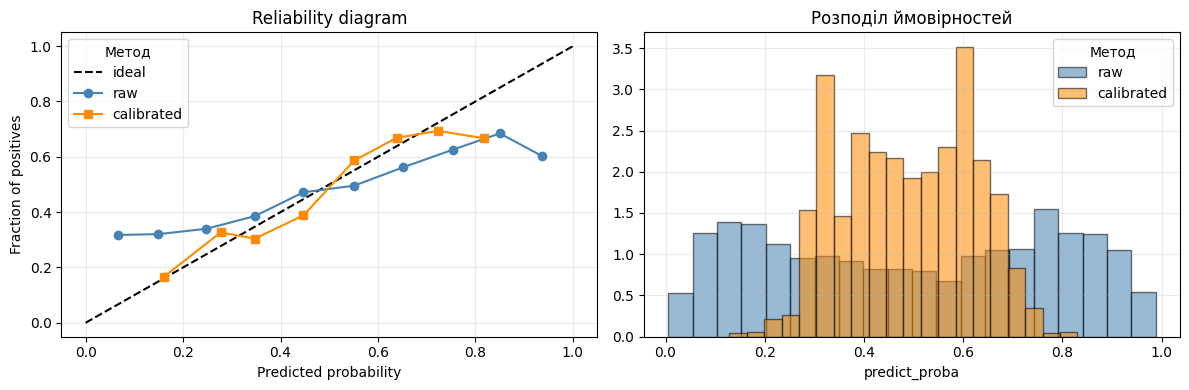

In [6]:
plot_calibration(
    df,
    feature_cols=['gross_summ', 'avg_session_time'],
    target_col='target',
    method='isotonic'
)